# Orbital magnetization of large flakes

The orbital magnetization is the magnetic moment of the currents that circulate in
the ground state. In a finite flake the position operator is well defined, and the
total moment is

$$M_z={\rm Tr}\left[f(H)\,m_z\right],\qquad
m_z=-\frac{1}{2}\left(\mathbf r\times\mathbf v\right)_z=-\frac{i}{2}\left(xHy-yHx\right),$$

with $\mathbf v=i[H,\mathbf r]$ and electrons of charge $-e$. We expand $f(H)$ in
Chebyshev polynomials, so the cost grows linearly with the number of sites. In the
bulk gap of a Chern insulator only the edge states change with the Fermi level, and
the Streda relation gives $dM_z/dE_F=CA/(2\pi)$, with $A$ the area of the flake.

2 pi (dM/dE_F)/A in the gap = 0.91


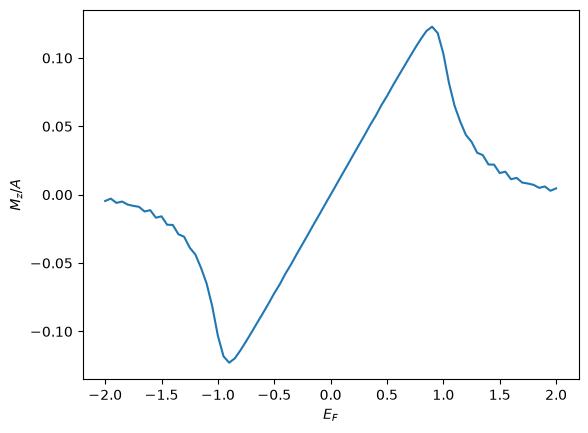

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import islands
g = islands.get_geometry(name="honeycomb",n=10,nedges=6) # 600 sites
h = g.get_hamiltonian(has_spin=False,is_sparse=True)
h.add_haldane(0.2) # Chern insulator, C=1, bulk gap of 1.8
efs = np.linspace(-2.,2.,81) # Fermi levels
m = h.get_orbital_magnetization(fermi=efs,T=0.02,trace="exact") # total moment
area = len(g.r)*3*np.sqrt(3)/4 # area of the flake
gap = np.abs(efs)<0.4 # Fermi levels inside the bulk gap
slope = np.polyfit(efs[gap],m[gap],1)[0] # dM/dE_F
print("2 pi (dM/dE_F)/A in the gap =",round(2*np.pi*slope/area,3))
plt.plot(efs,m/area)
plt.xlabel("$E_F$") ; plt.ylabel("$M_z/A$")
plt.show()

Inside the gap the moment grows linearly with $E_F$, and the slope gives $0.91$
times $C$. The edge current flows a little inside the edge, so it encloses less than
the whole area, and the ratio goes to 1 as the flake grows.

The derivative $dM_z/dE_F$ as a function of the Fermi level and of a sublattice mass
$M$ maps the phase diagram of the Haldane model. With $t_2=0.2$ the gap closes at
$M=4.5t_2=0.9$. Below it the derivative sits on the Streda plateau $C=1$ inside the
gap, and above it the flake is a trivial insulator, with no plateau.

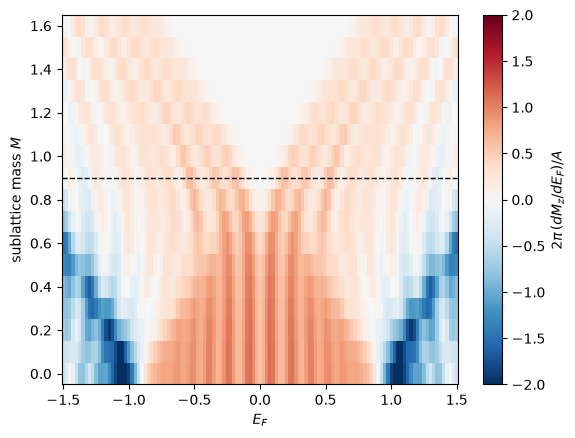

In [2]:
g = islands.get_geometry(name="honeycomb",n=7,nedges=6) # 266 sites
area = len(g.r)*3*np.sqrt(3)/4
efs = np.linspace(-1.5,1.5,121)
masses = np.linspace(0.,1.6,17)
dmap = []
for M in masses:
    h = g.get_hamiltonian(has_spin=False)
    h.add_haldane(0.2)
    h.add_sublattice_imbalance(M)
    m = h.get_orbital_magnetization(fermi=efs,T=0.03,mode="ED")
    dmap.append(2*np.pi*np.gradient(m,efs)/area) # in units of C
plt.pcolormesh(efs,masses,np.array(dmap),cmap="RdBu_r",shading="auto",vmin=-2,vmax=2)
plt.axhline(0.9,ls="--",c="black",lw=1) # gap closing, M = 4.5 t2
plt.colorbar(label=r"$2\pi\,(dM_z/dE_F)/A$")
plt.xlabel("$E_F$") ; plt.ylabel("sublattice mass $M$")
plt.show()

Below the dashed line the derivative sits on a plateau around $E_F=0$, the bulk
gap, which shrinks as $M$ grows and closes at $M=0.9$. The plateau is about $0.87$
rather than 1, the edge correction of this flake of 266 sites, and its stripes are
the discrete edge levels. Above the line the
window opens again, as the gap of a trivial insulator, and the derivative there is
zero: the edge states are gone, and with them the slope of the moment.

### Comparison with the literature
The commutator form of the total orbital magnetization of a finite flake, its
Chebyshev expansion with random vectors, and the Chern number from the value of
$dM_z/dE_F$ in the gap are those of Ref. [1].

[1] K. J. U. Vidarte, H. P. Veiga, J. M. Viana Parente Lopes, R. Cardias, A. Ferreira, T. P. Cysne and T. G. Rappoport, arXiv:2512.01575.